# Pincelada y Randomizer — versión corregida

Copia del notebook de Angie (`pincelada y randomizer.ipynb`, en la raíz del repositorio) con las correcciones marcadas con `CORREGIDO`. Incluye la línea que faltaba según la captura de pantalla (`img_evol.update_Hedge_Array()`) y el cambio de nombre del parámetro a `randomizer`.

**Ojo:** este notebook todavía es *búsqueda aleatoria* (crea 10 imágenes al azar y elige la mejor). La versión evolutiva completa está en `pintor_evolutivo/`.

In [1]:
import random
import math
from PIL import Image, ImageDraw
from collections import namedtuple
import numpy as np
from IPython.display import display   # CORREGIDO: para ver imagenes dentro del notebook

In [2]:
with Image.open("vanGogh2.jpeg") as imagen_original:
        img_RGB = imagen_original.convert("RGB")
        img_width = imagen_original.width
        img_height = imagen_original.height
        img_original_RGB = np.array(img_RGB)

img_shape = img_original_RGB.shape
img_type = img_original_RGB.dtype

In [3]:
# para que esta clase funcione tienes que correr la celda anterior que carga la imagen_original y sus parametros
class Pincelada:

    #inicializar una pincelada
    def __init__(self, points=[], size= 0, width=0, angle =0, color=(0,0,0), tipo = "line"):
        self.points = points        #array de puntos tipo (x,y), points = [(x_0,y_0), (x_1,y_1)...] 
        self.size = size
        self.width = width        #ancho de linea
        self.angle = angle        # inclinacion de la linea o medida del arco
        self.color = color        #en formato RGB - (r,g,b)
        self.tipo = tipo          #puede ser "line" o "arc"
        #datos adicionales necesarios para arcos:
        self.start = 0
        self.end = angle


    def print(self):
        if(self.tipo == "line"):
            print("[ points: "+str(self.points)+" , size: "+str(self.size)+ 
              " , width: "+str(self.width) + ", angle: "+str(self.angle) +
              ", color: "+str(self.color) + ", tipo: "+str(self.tipo) +  "]")
        else:
            print("[ points: "+str(self.points)+" , size: "+str(self.size)+ 
              " , width: "+str(self.width) + ", angle: "+str(self.angle) +
              ", color: "+str(self.color) + ", tipo: "+str(self.tipo) + 
              ", start: "+str(self.start) +  ", end: "+str(self.end) +   "]")

In [4]:
# para que esta clase funcione tienes que correr la celda que carga la imagen_original y sus parametros
# también la celda que contiene la clase pincelada

class Pincelada_Randomizer:
    
    # inicializa los parametros para poder usar los metodos random 
    def __init__(self,min_size = 45, max_size = 60,min_angle = 0, max_angle = 240,min_width=15, max_width =20, factor_arco= 0.6):
        self.min_size = min_size
        self.max_size = max_size
        self.min_angle = min_angle
        self.max_angle = max_angle
        self.min_width = min_width
        self.max_width = max_width
        self.factor_arco = factor_arco 


    def generate_Random_Pincelada(self, tipo = ""):
        pincelada = Pincelada()
        pincelada.color = self.random_Color()
        if(tipo == ""):
            pincelada.tipo = self.random_Tipo()
        else:
            pincelada.tipo = tipo

        pincelada.width = self.random_Value_In_Range(self.min_width, self.max_width)
        pincelada.size = self.random_Value_In_Range(self.min_size, self.max_size)  # CORREGIDO: decia (min_size, min_size)
        pincelada.angle = self.random_Value_In_Range(self.min_angle, self.max_angle)
        
        # los puntos se eligen despues de determinar size y angle y tipo
        pincelada.points = self.random_Points(pincelada.size, pincelada.angle, pincelada.tipo)

        #start y end se eligen despues de determinar tipo y angle
        if(pincelada.tipo == "arc"):
            pincelada.start, pincelada.end = self.random_Start_End(pincelada.angle)
            pincelada.width = math.ceil(pincelada.width* self.factor_arco)
        return pincelada

    # asigna color dado un punto aleatorio en la imagen
    # toma como referencia el color en la imagen original
    def random_Color(self):
        x = random.randint(0,img_width-1)
        y = random.randint(0,img_height-1)   # CORREGIDO: decia img_width (se sale si la imagen es horizontal)
        color = img_original_RGB[y][x]
        
        return tuple(color)

    # regresa un valor aleatorio en un rango [a,b]
    def random_Value_In_Range(self, a, b):
        if(a < b):
            return random.randint(a,b)
        else:
            return a

    def random_Tipo(self):
        shape_types = ["line", "arc"]
        return random.choice(shape_types)

    def random_Start_End(self, angle):
        start = random.randint(0,359)
        end = (start + angle) % 360   # CORREGIDO: el circulo tiene 360 grados
        return start, end

    def random_Points(self, size, angle, tipo):
        #convertir a radianes
        angle = math.radians(angle)
        
        #encontramos la proyeccion en x y y de la pincelada para ese angulo y r = size
        x_length = size*math.cos(angle)
        y_length = size*math.sin(angle)

        #inicializamos puntos random dentro de una caja para que no se salgan las cosas
        # CORREGIDO: con angulos > 90 grados x_length (o y_length) es NEGATIVO y la caja quedaba mal
        # (podian salir puntos fuera de la imagen). Ahora la caja se calcula con el signo correcto.
        x_0 = random.randint(math.ceil(max(0, -x_length)), math.floor(img_width - 1 - max(0, x_length)))
        y_0 = random.randint(math.ceil(max(0, -y_length)), math.floor(img_height - 1 - max(0, y_length)))

        #se elige segundo punto hacia adelante o hacia atras - no se sale por nuestra eleccion del primer punto
        x_1 = x_0 + x_length
        y_1 = y_0 + y_length
        
        #regresamos el conjunto de dos puntos
        if(tipo == "line"):
            #para lineas no importa el orden
            return [(x_0,y_0),(x_1,y_1)]
        else:
            #para arcos, las coordenadas deben estar ordenadas de menor a mayor
            x_min, x_max = sorted([x_0,x_1]) 
            y_min, y_max = sorted([y_0,y_1]) 
            return [(x_min, y_min), (x_max + 15, y_max + 10)]
        

    def clamp(self,x, minimum, maximum):
        if x < minimum:
            return minimum
        if x > maximum:
            return maximum
        return x
        

In [5]:
class ImagenEvolutiva:

    def __init__(self):
        self.lista_pinceladas =[]  
        self.hedge_array = np.zeros((img_height, img_width))
        #self.image - se inicializa con generate_image
    
    def add_Pincelada(self,pincelada):
         self.lista_pinceladas.append(pincelada)

    # antes de llamar esta funcion se tiene que usar generate_image
    def update_Hedge_Array(self):
        img_temp = Image.new("RGB", [img_width, img_height])
        draw_img = ImageDraw.Draw(img_temp)
        num_pinceladas = len(self.lista_pinceladas)

        # dibuja todas las pinceladas en la lista pero las dibuja en blanco
        for pincelada in self.lista_pinceladas:
            if(pincelada.tipo == "line"):
                draw_img.line(xy=pincelada.points, fill = (255,255,255), width = pincelada.width)
            else:
                draw_img.arc(xy=pincelada.points, start = pincelada.start, end=pincelada.end, fill = (255,255,255), width = pincelada.width)

        
        array_temp = np.array(img_temp)
        #actualiza el hedge array con los nuevos 1's
        filas, columnas = np.where(np.all(array_temp == 255, axis=-1))
        self.hedge_array[filas, columnas] = 1
        
        del img_temp, draw_img, num_pinceladas,filas, columnas, array_temp
        
    def generate_image(self):
        #crea image 
        image = Image.new("RGB", [img_width, img_height])
        draw_img = ImageDraw.Draw(image)
        num_pinceladas = len(self.lista_pinceladas)
        
        # dibuja todas las pinceladas en la lista
        for pincelada in self.lista_pinceladas:
            if(pincelada.tipo == "line"):
                draw_img.line(xy=pincelada.points, fill = pincelada.color, width = pincelada.width)
            else:
                draw_img.arc(xy=pincelada.points, start = pincelada.start, end=pincelada.end, fill = pincelada.color, width = pincelada.width)
        self.image = image
        del draw_img, num_pinceladas
        return image   # CORREGIDO: antes no regresaba nada (show_Best_Option fallaba)

In [6]:
class AlgoritmoEvolutivo:

    def __init__(self,number_imagenes=10,number_pinceladas=100):
        self.number_chromosomes = number_imagenes 
        self.number_genes = number_pinceladas
        self.hedge_lambda = 0.2   # CORREGIDO: con 0 conviene pintar poco (solo se mide donde se pinto)
        self.fitness = []
        self.list_chromosomes = []
        self.parametros_chromosomas = {"rango_size": (35,55), "rango_angle": (0,200), 
                                       "rango_width": (12,18), "factor_arco": 0.2}

    # CORREGIDO (antes marcado "ESTA MAL"): usaba variables que no existian (img_original, img_evol)
    # y restaba el OBJETO ImagenEvolutiva en vez de su imagen.
    def mean_square_error(self,img_evolutiva):
        filas, columnas = np.where(img_evolutiva.hedge_array == 1)
        max_error_posible = 65025 
        error_contenido = max_error_posible
        porcent_hedge = 0.0
        # si al menos un pixel fue coloreado
        if len(filas) != 0: 
            img_original_signo = img_original_RGB.astype(np.int32) #para evitar negativos cuando haces la resta
            img_original_signo = img_original_signo[filas, columnas]
            img_evol_signo = np.array(img_evolutiva.image).astype(np.int32)
            img_evol_signo = img_evol_signo[filas, columnas]
            error_contenido = (img_original_signo - img_evol_signo)**2
            error_contenido = np.mean(error_contenido)
            porcent_hedge = len(filas)/((len(img_evolutiva.hedge_array) * len(img_evolutiva.hedge_array[0]))) 
        error_contenido = (error_contenido/max_error_posible) + (self.hedge_lambda * (1 - porcent_hedge))
        #print(error_contenido)
        return error_contenido

    # CORREGIDO: reinicia la lista de fitness y dibuja cada imagen antes de medirla
    def calculate_Fitness(self):
        self.fitness = []
        for i in range(self.number_chromosomes):
            img_evol = self.list_chromosomes[i]
            img_evol.generate_image()
            value = self.mean_square_error(img_evol)
            self.fitness.append(value)
            
    # CORREGIDO: generate_image ahora regresa la imagen; se muestra con display (Jupyter)
    def show_Best_Option(self):
        best_option = self.list_chromosomes[self.fitness.index(min(self.fitness))]
        img_evol = best_option.generate_image()
        display(img_evol)
        return img_evol

    #Crea una lista de chromosomas-imagenes
    # CORREGIDO (captura de pantalla): el parametro se llama "randomizer", se usa self en lugar de
    # la variable global algoritmo_evol, el ciclo interno usa j y falta update_Hedge_Array().
    def create_Chromosomes(self, randomizer):
        self.list_chromosomes = []
        for i in range(0, self.number_chromosomes): # numero de imagenes
            #Crea una imagen
            img_evol = ImagenEvolutiva()
    
            for j in range(0, self.number_genes):# numero de pinceladas por imagen      
                # agregar pinceladas a la imagen
                pincelada = randomizer.generate_Random_Pincelada()
                img_evol.add_Pincelada(pincelada)

            img_evol.update_Hedge_Array()   # <- linea que faltaba (captura de pantalla)
            #agrega la imagen a la lista de imagenes/chromosomas 
            self.list_chromosomes.append(img_evol)

    

In [7]:
# inicializa el randomizer y el algoritmo evolutivo
randomizer = Pincelada_Randomizer()
algoritmo_evol = AlgoritmoEvolutivo()

In [8]:
algoritmo_evol.create_Chromosomes(randomizer)

In [9]:
algoritmo_evol.calculate_Fitness()

In [10]:
algoritmo_evol.fitness   # valores en [0, 1.2]: menor es mejor

[np.float64(0.22741468070001655),
 np.float64(0.2020100039078428),
 np.float64(0.21592244682268133),
 np.float64(0.209164878276134),
 np.float64(0.20568750206016528),
 np.float64(0.2190067270480171),
 np.float64(0.21665853671445856),
 np.float64(0.21375047870266645),
 np.float64(0.2180735045132408),
 np.float64(0.21640982959222071)]

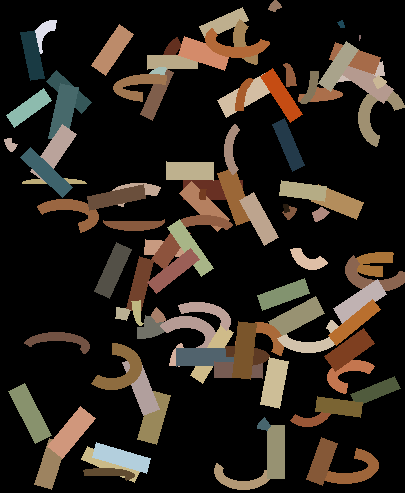

In [11]:
# Muestra la mejor de las imagenes aleatorias
mejor = algoritmo_evol.show_Best_Option()

In [12]:
# CORREGIDO: img_evol no existia fuera de la clase; se toma el primer cromosoma
img_evol = algoritmo_evol.list_chromosomes[0]
print('pixeles cubiertos:', int(img_evol.hedge_array.sum()), 'de', img_evol.hedge_array.size)

pixeles cubiertos: 49777 de 199665


In [13]:
#aquí puedes cambiar los parametros de las pinceladas
#si quieres un width o un size etc especifico, pon el rango como (valor,valor)
#aqui por ejemplo para width queda como min_width = max_width
randomizer = Pincelada_Randomizer(min_width=10, max_width=10, factor_arco= 0.5)

#genera 50 pinceladas random
lista = []
for i in range(0,500):
    pincelada = randomizer.generate_Random_Pincelada()
    lista.append(pincelada)

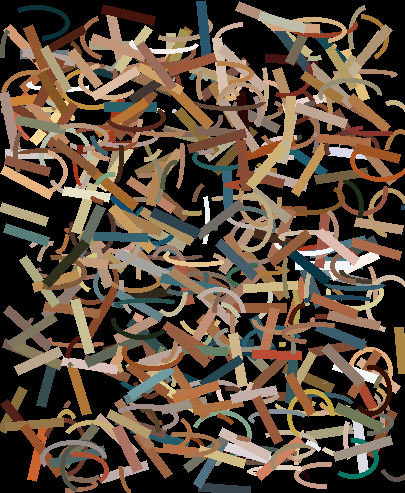

In [14]:
#crea y muestra la imagen

image = Image.new("RGB", [img_width, img_height])
draw_img = ImageDraw.Draw(image)
#pincelada.width = math.ceil(pincelada.width*0.2)
for pincelada in lista:
    if(pincelada.tipo == "line"):
        draw_img.line(xy=pincelada.points, fill = pincelada.color, width = pincelada.width)
    else:
        draw_img.arc(xy=pincelada.points, start = pincelada.start, end=pincelada.end, fill = pincelada.color, width = pincelada.width)

display(image)   # CORREGIDO: image.show() abre una ventana externa